# Shoplifting Detection - video classification

In [15]:
import os, re, glob, zipfile, random, math, copy, warnings
import numpy as np, pandas as pd, cv2
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold, StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
warnings.filterwarnings("ignore")

DATA_URL = "https://drive.google.com/file/d/1KCKfyIGbQi8a7bIYta3LM8dFStxVzVX-/view?usp=sharing"          # link to the zip file; leave empty to use a dataset attached to the notebook
WORK = "/kaggle/working" if os.path.isdir("/kaggle/working") else "./work"
os.makedirs(WORK, exist_ok=True)

T, K = 16, 32          # frames per clip fed to the model / frames cached per video
CACHE_SIZE, IMG = 128, 112
BATCH, EPOCHS, LR, WD, PATIENCE = 16, 80, 1e-3, 1e-2, 25
SEED = 42

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = device.type == "cuda"
print(device)

cuda


## Data

In [2]:
VIDEO_EXT = {".mp4", ".avi", ".mov", ".mkv", ".wmv", ".flv", ".webm", ".mpg", ".mpeg"}

def fetch(url, dst):
    if os.path.isdir(dst) and os.listdir(dst):
        return dst
    os.makedirs(dst, exist_ok=True)
    zpath = os.path.join(WORK, "data.zip")
    if "drive.google.com" in url:
        import gdown
        gdown.download(url, zpath, quiet=False, fuzzy=True)
    else:
        import requests
        with requests.get(url, stream=True, timeout=60) as r:
            r.raise_for_status()
            with open(zpath, "wb") as f:
                for chunk in r.iter_content(1 << 20):
                    f.write(chunk)
    with zipfile.ZipFile(zpath) as z:
        z.extractall(dst)
    os.remove(zpath)
    return dst

ROOT = fetch(DATA_URL, os.path.join(WORK, "data")) if DATA_URL else "/kaggle/input"
videos = sorted(p for p in glob.glob(os.path.join(ROOT, "**", "*"), recursive=True)
                if os.path.splitext(p)[1].lower() in VIDEO_EXT)
print(len(videos), "videos")
print(pd.Series([os.path.relpath(os.path.dirname(p), ROOT) for p in videos]).value_counts().head(20))

Downloading...
From (original): https://drive.google.com/uc?id=1KCKfyIGbQi8a7bIYta3LM8dFStxVzVX-
From (redirected): https://drive.google.com/uc?id=1KCKfyIGbQi8a7bIYta3LM8dFStxVzVX-&confirm=t&uuid=e95735e8-d0a5-47a8-9f24-58420649ce7c
To: /kaggle/working/data.zip
100%|██████████| 1.78G/1.78G [00:12<00:00, 140MB/s] 


855 videos
Shop DataSet/non shop lifters    531
Shop DataSet/shop lifters        324
Name: count, dtype: int64


In [3]:
LABEL_MAP = {}   # only if labels are not inferred, e.g. {"class_a": 0, "class_b": 1}
NEG = re.compile(r"non|normal|(?<![a-z])no(?![a-z])|negative|regular|honest|clean|genuine")
POS = re.compile(r"shoplift|theft|steal|stole|thie|robber")
SPLITS = {"train": "train", "training": "train", "val": "val", "valid": "val",
          "validation": "val", "test": "test", "testing": "test"}

def infer(path):
    parts = os.path.relpath(path, ROOT).lower().split(os.sep)
    parts[-1] = os.path.splitext(parts[-1])[0]
    label, split = None, None
    for s in list(reversed(parts[:-1])) + [parts[-1]]:
        if label is None:
            if s in LABEL_MAP: label = LABEL_MAP[s]
            elif NEG.search(s): label = 0
            elif POS.search(re.sub("[^a-z0-9]+", "", s)): label = 1
        if split is None and s in SPLITS: split = SPLITS[s]
    return label, split

df = pd.DataFrame({"path": videos})
df["label"], df["split"] = zip(*df.path.map(infer))
print(df.label.value_counts(dropna=False).to_dict(), df.split.value_counts(dropna=False).to_dict())
df = df.dropna(subset=["label"]).reset_index(drop=True)
df["label"] = df.label.astype(int)
assert df.label.nunique() == 2, "Labels not inferred. Fill LABEL_MAP with the class folder names printed above."

{0: 531, 1: 324} {None: 855}


## Frame sampling

In [4]:
def sample_indices(n, t, jitter=False):
    skip = n / t
    pos = (np.arange(t) + (np.random.rand(t) if jitter else 0.5)) * skip
    return np.clip(pos.astype(int), 0, n - 1)

for n in [1, 5, 16, 17, 31, 100, 299, 1000, 5000]:
    i = sample_indices(n, T)
    assert len(i) == T and i.min() >= 0 and i.max() < n and (np.diff(i) >= 0).all()
    if n >= T:
        assert i[0] < n / T and i[-1] >= n - n / T - 1 and np.ptp(np.diff(i)) <= 1
for n in [20, 100, 450]:
    print(n, sample_indices(n, T).tolist())

20 [0, 1, 3, 4, 5, 6, 8, 9, 10, 11, 13, 14, 15, 16, 18, 19]
100 [3, 9, 15, 21, 28, 34, 40, 46, 53, 59, 65, 71, 78, 84, 90, 96]
450 [14, 42, 70, 98, 126, 154, 182, 210, 239, 267, 295, 323, 351, 379, 407, 435]


## Frame cache and metadata

In [5]:
def extract(path):
    cap = cv2.VideoCapture(path)
    n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS) or np.nan
    w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    if n <= 0:
        n = 0
        while cap.grab(): n += 1
        cap.release(); cap = cv2.VideoCapture(path)
    if n <= 0:
        return None
    need = sample_indices(n, K)
    keep, got, i = set(need.tolist()), {}, 0
    while i <= need.max() and cap.grab():
        if i in keep:
            ok, f = cap.retrieve()
            if ok:
                f = cv2.cvtColor(f, cv2.COLOR_BGR2RGB)
                got[i] = cv2.resize(f, (CACHE_SIZE, CACHE_SIZE), interpolation=cv2.INTER_AREA)
        i += 1
    cap.release()
    if not got:
        return None
    ks = np.array(sorted(got))
    near = ks[np.abs(ks[None] - need[:, None]).argmin(1)]
    return dict(n=n, fps=fps, w=w, h=h), np.stack([got[k] for k in near])

res = Parallel(n_jobs=-1)(delayed(extract)(p) for p in tqdm(df.path))
good = np.array([r is not None for r in res])
print("unreadable videos:", (~good).sum())
df = pd.concat([df[good].reset_index(drop=True), pd.DataFrame([r[0] for r in res if r is not None])], axis=1)
frames = np.stack([r[1] for r in res if r is not None])
del res
df["sec"] = df.n / df.fps
print(frames.shape, frames.nbytes / 1e9, "GB")
labels = df.label.values

  0%|          | 0/855 [00:00<?, ?it/s]

unreadable videos: 0
(855, 32, 128, 128, 3) 1.34479872 GB


## EDA

label
normal         531
shoplifting    324
             n     fps     sec      w      h
count   855.00  855.00  855.00  855.0  855.0
mean    331.42   24.95   13.28  704.0  576.0
std     119.38    0.09    4.78    0.0    0.0
min      75.00   24.75    3.00  704.0  576.0
25%     250.00   25.00   10.02  704.0  576.0
50%     325.00   25.00   13.00  704.0  576.0
75%     396.00   25.00   16.00  704.0  576.0
max    1850.00   25.00   74.00  704.0  576.0


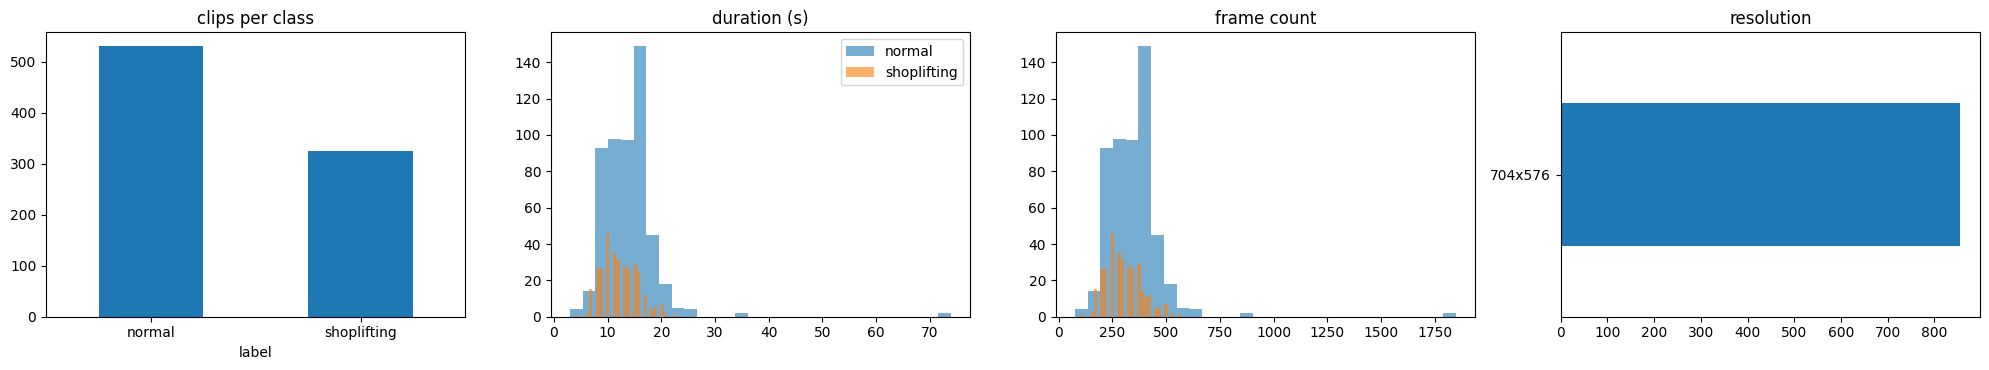

In [6]:
names = {0: "normal", 1: "shoplifting"}
print(df.label.map(names).value_counts().to_string())
print(df[["n", "fps", "sec", "w", "h"]].describe().round(2).to_string())

fig, ax = plt.subplots(1, 4, figsize=(20, 3.8))
df.label.map(names).value_counts().plot.bar(ax=ax[0], title="clips per class", rot=0)
for l in (0, 1):
    ax[1].hist(df.sec[df.label == l].dropna(), bins=30, alpha=.6, label=names[l])
    ax[2].hist(df.n[df.label == l], bins=30, alpha=.6, label=names[l])
ax[1].set_title("duration (s)"); ax[2].set_title("frame count"); ax[1].legend()
(df.w.astype(str) + "x" + df.h.astype(str)).value_counts().head(6).plot.barh(ax=ax[3], title="resolution")
plt.tight_layout(); plt.show()

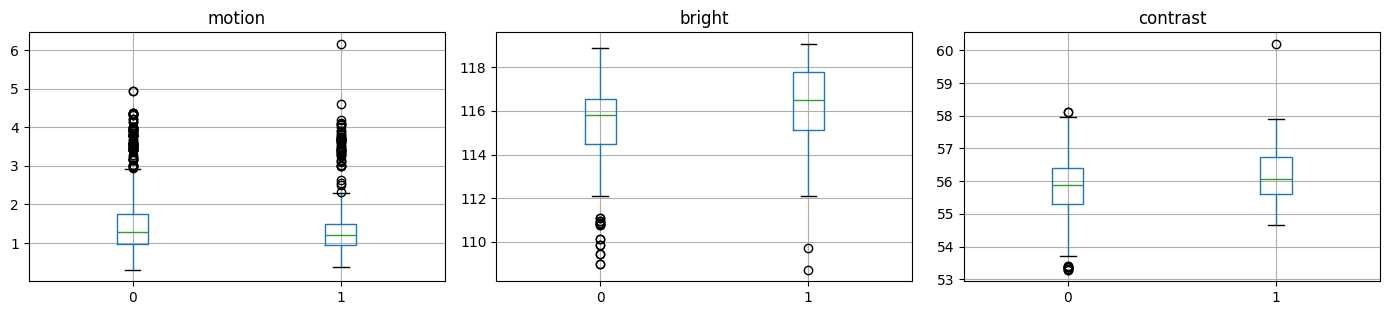

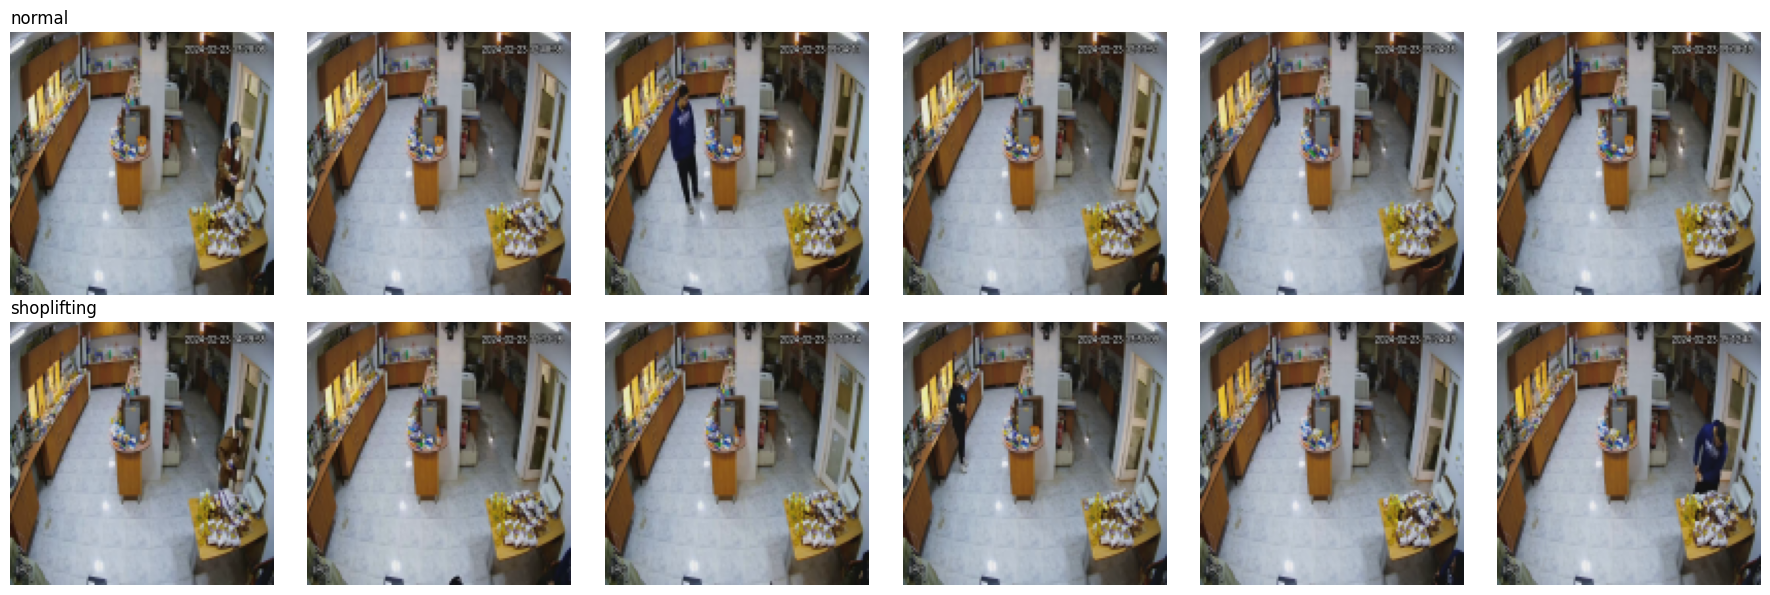

In [7]:
f32 = frames[:, :, ::4, ::4].astype(np.float32)
df["motion"] = np.abs(np.diff(f32, axis=1)).mean((1, 2, 3, 4))
df["bright"] = f32.mean((1, 2, 3, 4))
df["contrast"] = f32.std((2, 3, 4)).mean(1)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
for a, c in zip(ax, ["motion", "bright", "contrast"]):
    df.boxplot(column=c, by="label", ax=a); a.set_title(c); a.set_xlabel("")
plt.suptitle(""); plt.tight_layout(); plt.show()

rng = np.random.RandomState(0)
fig, ax = plt.subplots(2, 6, figsize=(18, 6))
for r, l in enumerate((0, 1)):
    for c, j in enumerate(rng.choice(np.where(labels == l)[0], 6, replace=False)):
        ax[r, c].imshow(frames[j, K // 2]); ax[r, c].axis("off")
    ax[r, 0].set_title(names[l], loc="left")
plt.tight_layout(); plt.show()

In [8]:
feat = ["sec", "n", "fps", "w", "h", "motion", "bright", "contrast"]
X = df[feat].fillna(df[feat].median())
single = X.apply(lambda c: roc_auc_score(labels, c)).round(3)
base = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced"))
p = cross_val_predict(base, X, labels, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
print(single.to_string())
print("metadata-only baseline AUC:", round(roc_auc_score(labels, p), 3))

sec         0.383
n           0.374
fps         0.396
w           0.500
h           0.500
motion      0.463
bright      0.639
contrast    0.593
metadata-only baseline AUC: 0.755


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 194MB/s] 


  0%|          | 0/78 [00:00<?, ?it/s]

candidate pairs: 9264 of 190653
pairs >= GROUP_THR: 106 | >= DUP_THR: 0


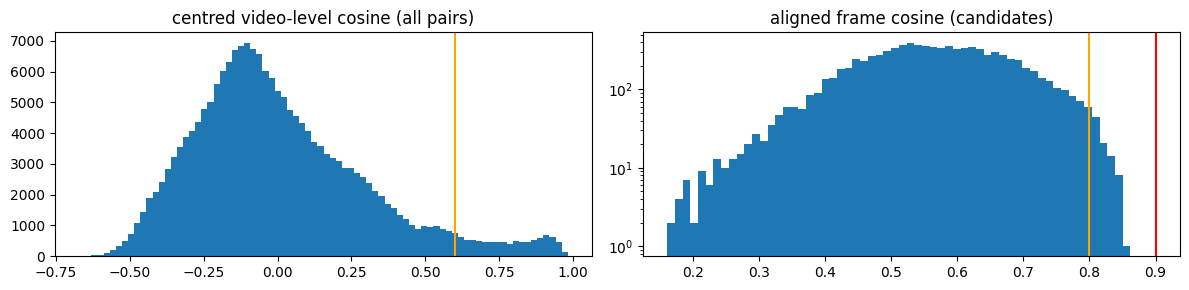

In [24]:
import torchvision
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components

CAND_THR = 0.60    # centred video-level cosine: only pairs above this are examined further
DUP_THR = 0.90     # mean aligned frame-by-frame cosine >= this -> duplicate, dropped (one copy kept)
GROUP_THR = 0.80   # >= this -> same group, kept in the same split (prevents leakage)
MAX_DROP = 0.3    # safety stop: refuse to drop more than this fraction of videos

emb_net = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V2)
emb_net.fc = nn.Identity()
emb_net = emb_net.to(device).eval()
_m, _s = (torch.tensor(v, device=device).view(1, 3, 1, 1) for v in ([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]))

@torch.no_grad()
def frame_embeddings(frames, bs=8):
    out = []
    for i in tqdm(range(0, len(frames), bs)):
        x = torch.from_numpy(frames[i:i + bs]).to(device)              # (B, K, H, W, 3) uint8
        B, k = x.shape[:2]
        x = x.flatten(0, 1).permute(0, 3, 1, 2).float().div_(255)
        x = F.interpolate(x, size=224, mode="bilinear", align_corners=False)
        with torch.autocast(device.type, enabled=AMP):
            e = emb_net((x - _m) / _s).float()
        out.append(e.view(B, k, -1).cpu())
    return torch.cat(out).numpy()                                      # (N, K, D) raw

femb = frame_embeddings(frames)
del emb_net
torch.cuda.empty_cache()

# centre by the dataset mean: removes the shared camera/background component that makes every clip look alike
fc = femb - femb.reshape(-1, femb.shape[-1]).mean(0)
fc /= np.linalg.norm(fc, axis=-1, keepdims=True) + 1e-8                 # unit-length centred frame embeddings
emb = fc.mean(1)
emb /= np.linalg.norm(emb, axis=1, keepdims=True) + 1e-8                # per-video average embedding

def pair_scores(emb, fc, cand_thr):
    # candidates from averaged-embedding cosine, confirmed by mean aligned frame-by-frame cosine
    s = emb @ emb.T
    P = np.argwhere(np.triu(s >= cand_thr, 1))
    out = np.full(s.shape, -1.0, dtype=np.float32)
    for i in range(0, len(P), 256):
        a, b = P[i:i + 256].T
        out[a, b] = out[b, a] = (fc[a] * fc[b]).sum(-1).mean(1)
    return s, out

def clusters(s, thr):
    return connected_components(csr_matrix(s >= thr), directed=False)[1]

vsim, sim = pair_scores(emb, fc, CAND_THR)
upper = sim[np.triu_indices(len(sim), 1)]
upper = upper[upper > -1]
print("candidate pairs:", len(upper), "of", len(emb) * (len(emb) - 1) // 2)
print("pairs >= GROUP_THR:", int((upper >= GROUP_THR).sum()), "| >= DUP_THR:", int((upper >= DUP_THR).sum()))
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
ax[0].hist(vsim[np.triu_indices(len(vsim), 1)], bins=80); ax[0].axvline(CAND_THR, c="orange")
ax[0].set_title("centred video-level cosine (all pairs)")
ax[1].hist(upper, bins=60); ax[1].set_yscale("log"); ax[1].set_title("aligned frame cosine (candidates)")
ax[1].axvline(GROUP_THR, c="orange"); ax[1].axvline(DUP_THR, c="r")
plt.tight_layout(); plt.show()

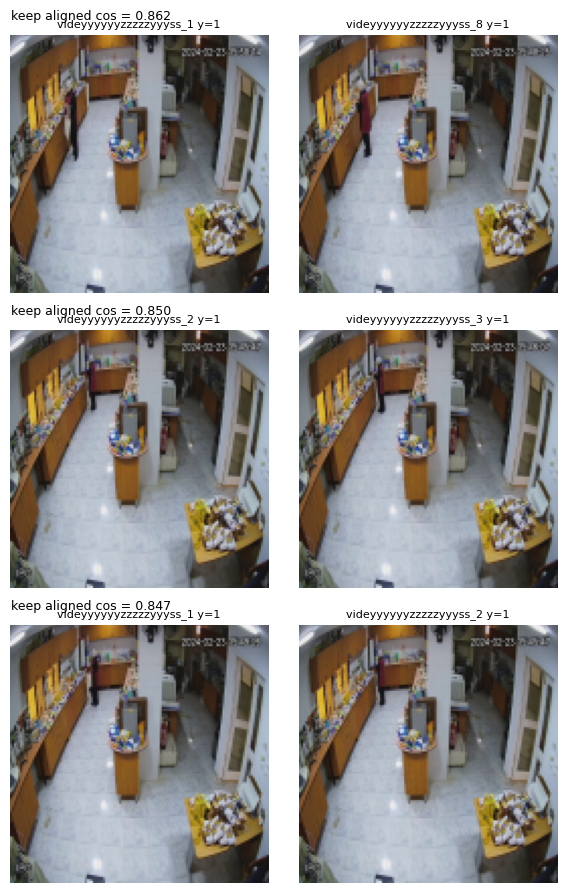

In [25]:
# Look at pairs just above and just below DUP_THR before trusting the thresholds
iu = np.triu_indices(len(df), 1)
sc = sim[iu]
order = np.argsort(-sc)
above = [t for t in order if sc[t] >= DUP_THR][-3:]       # weakest accepted duplicates
below = [t for t in order if -1 < sc[t] < DUP_THR][:3]    # strongest rejected pairs
pairs = above + below
fig, ax = plt.subplots(max(len(pairs), 1), 2, figsize=(6, 3 * max(len(pairs), 1)), squeeze=False)
for r, t in enumerate(pairs):
    a, b = iu[0][t], iu[1][t]
    for c, j in enumerate((a, b)):
        ax[r, c].imshow(frames[j, K // 2]); ax[r, c].axis("off")
        ax[r, c].set_title(f"{os.path.basename(df.path[j])[:22]} y={labels[j]}", fontsize=8)
    ax[r, 0].text(0, -8, ("DUP " if sc[t] >= DUP_THR else "keep ") + f"aligned cos = {sc[t]:.3f}", fontsize=9)
plt.tight_layout(); plt.show()

In [26]:
# Drop duplicates (keep the first copy of each cluster)
dup = clusters(sim, DUP_THR)
conflict = pd.Series(labels).groupby(dup).nunique().gt(1)
print("duplicate clusters with conflicting labels:", int(conflict.sum()))
keep = np.sort(np.unique(dup, return_index=True)[1])
conf_ids = set(np.where(conflict)[0])
keep = np.array([k for k in keep if dup[k] not in conf_ids])   # conflicting-label clusters are ambiguous: drop entirely
frac = 1 - len(keep) / len(df)
print(f"would drop {len(df) - len(keep)} of {len(df)} videos ({frac:.1%})")
assert frac <= MAX_DROP, "too many drops: check the plots above and raise DUP_THR / CAND_THR before continuing"

df = df.iloc[keep].reset_index(drop=True)
frames, emb, fc, labels = frames[keep], emb[keep], fc[keep], labels[keep]
sim = sim[np.ix_(keep, keep)]
group = clusters(sim, GROUP_THR)            # near-duplicate groups used for the split
print("videos:", len(df), "| groups:", group.max() + 1, "| largest group:", np.bincount(group).max())


duplicate clusters with conflicting labels: 0
would drop 0 of 618 videos (0.0%)
videos: 618 | groups: 562 | largest group: 15


## Split

In [27]:
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedGroupKFold

# group-aware, stratified ~70/15/15 split: near-duplicate videos never straddle train/val/test
def group_split(idx, n_splits):
    f = next(iter(StratifiedGroupKFold(n_splits, shuffle=True, random_state=SEED).split(idx, labels[idx], group[idx])))
    return idx[f[0]], idx[f[1]]

rest, te_idx = group_split(np.arange(len(df)), 7)
tr_idx, va_idx = group_split(rest, 6)

for a, b in ((tr_idx, va_idx), (tr_idx, te_idx), (va_idx, te_idx)):
    assert not set(group[a]) & set(group[b]), "group leakage between splits"
    print("max cross-split cosine similarity:", round(float(sim[np.ix_(a, b)].max()), 4))   # must be < GROUP_THR
print(pd.DataFrame({k: pd.Series(labels[v]).value_counts() for k, v in
                    dict(train=tr_idx, val=va_idx, test=te_idx).items()}).rename(index=names).to_string())

max cross-split cosine similarity: 0.7966
max cross-split cosine similarity: 0.7981
max cross-split cosine similarity: 0.7986
             train  val  test
normal         232   33    32
shoplifting    228   43    50


## Augmentation and dataset

In [28]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def augment(x, train):
    # x: (T, 3, H, W) in [0, 1]; every random parameter is drawn once and applied to all frames
    H, W = x.shape[-2:]
    if train:
        if random.random() < 0.5:
            x = x.flip(-1)
        s = random.uniform(0.7, 1.0)
        r = math.exp(random.uniform(math.log(3 / 4), math.log(4 / 3)))
        ch = min(H, int(round(H * math.sqrt(s / r))))
        cw = min(W, int(round(W * math.sqrt(s * r))))
        top, left = random.randint(0, H - ch), random.randint(0, W - cw)
        x = x[..., top:top + ch, left:left + cw]
    x = F.interpolate(x, size=(IMG, IMG), mode="bilinear", align_corners=False)
    if train:
        b, c, sat = (random.uniform(0.8, 1.2) for _ in range(3))
        x = x * b
        x = (x - x.mean()) * c + x.mean()
        g = x.mean(1, keepdim=True)
        x = (g + (x - g) * sat).clamp(0, 1)
    return x

class ClipDS(torch.utils.data.Dataset):
    def __init__(self, idx, train):
        self.idx, self.train = np.asarray(idx), train
    def __len__(self):
        return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]
        if self.train:
            n = random.randint(int(0.6 * K), K)
            sel = random.randint(0, K - n) + sample_indices(n, T, jitter=True)
        else:
            sel = sample_indices(K, T)
        x = torch.from_numpy(frames[j][sel]).permute(0, 3, 1, 2).float().div_(255)
        x = (augment(x, self.train) - MEAN) / STD
        return x, torch.tensor(float(labels[j]))

NW = min(4, os.cpu_count() or 1)
def make_loader(idx, train):
    return torch.utils.data.DataLoader(ClipDS(idx, train), batch_size=BATCH, shuffle=train, drop_last=train,
                                       num_workers=NW, pin_memory=AMP, persistent_workers=NW > 0)
train_dl, val_dl, test_dl = make_loader(tr_idx, True), make_loader(va_idx, False), make_loader(te_idx, False)

augmentation identical across frames: ok
dataset shape (T, C, H, W): (16, 3, 112, 112)


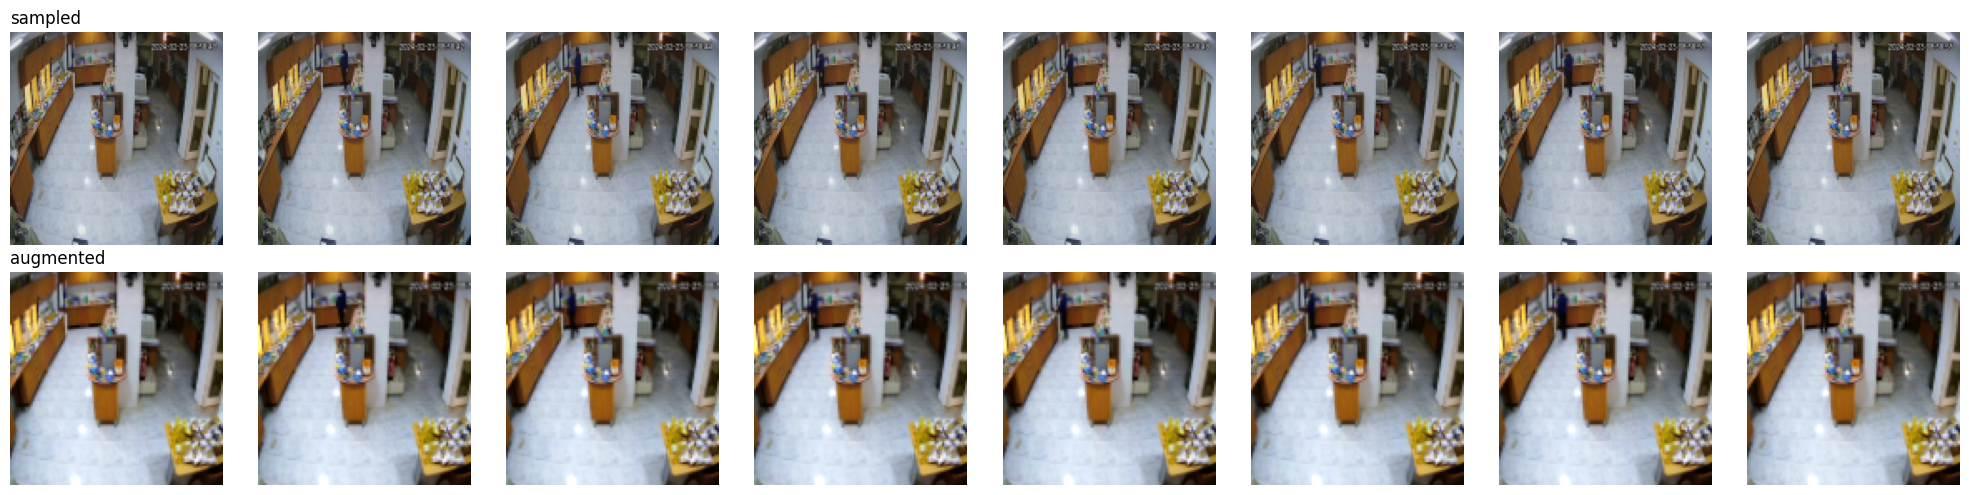

In [29]:
base_frame = torch.rand(1, 3, CACHE_SIZE, CACHE_SIZE)
for _ in range(10):
    out = augment(base_frame.repeat(T, 1, 1, 1), True)
    assert out.shape == (T, 3, IMG, IMG) and all(torch.allclose(out[0], o) for o in out)
print("augmentation identical across frames: ok")

for ds in (ClipDS(tr_idx, True), ClipDS(va_idx, False)):
    assert all(ds[i][0].shape == (T, 3, IMG, IMG) for i in range(min(8, len(ds))))
print("dataset shape (T, C, H, W):", tuple(ds[0][0].shape))

x, _ = ClipDS(tr_idx[:1], True)[0]
raw = frames[tr_idx[0]][sample_indices(K, T)]
x = (x * STD + MEAN).clamp(0, 1).permute(0, 2, 3, 1).numpy()
fig, ax = plt.subplots(2, 8, figsize=(20, 5))
for k in range(8):
    ax[0, k].imshow(raw[k * 2]); ax[1, k].imshow(x[k * 2]); ax[0, k].axis("off"); ax[1, k].axis("off")
ax[0, 0].set_title("sampled", loc="left"); ax[1, 0].set_title("augmented", loc="left")
plt.tight_layout(); plt.show()

## Model: from-scratch residual CNN (RGB + motion) with LSTM, attention pooling and appearance shortcut

In [30]:
class Block(nn.Module):
    def __init__(self, cin, cout, stride):
        super().__init__()
        self.c1, self.b1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False), nn.BatchNorm2d(cout)
        self.c2, self.b2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False), nn.BatchNorm2d(cout)
        self.sk = (nn.Identity() if stride == 1 and cin == cout else
                   nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout)))
    def forward(self, x):
        y = F.relu(self.b1(self.c1(x)), inplace=True)
        return F.relu(self.b2(self.c2(y)) + self.sk(x), inplace=True)

class Net(nn.Module):
    def __init__(self, d=256, h=128, drop=0.25):
        super().__init__()
        self.enc = nn.Sequential(
            nn.Conv2d(6, 32, 3, 2, 1, bias=False), nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            Block(32, 64, 2), Block(64, 64, 1), Block(64, 128, 2), Block(128, 128, 1),
            Block(128, 256, 2), Block(256, 256, 1), nn.AdaptiveAvgPool2d(1), nn.Flatten())
        for m in self.enc.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
        for m in self.enc.modules():
            if isinstance(m, Block):
                nn.init.zeros_(m.b2.weight)
        self.proj = nn.Sequential(nn.Linear(256, d), nn.LayerNorm(d), nn.GELU())
        self.gru = nn.LSTM(d, h, batch_first=True, bidirectional=True)
        self.att = nn.Linear(2 * h, 1)
        self.head = nn.Sequential(nn.Dropout(drop), nn.Linear(4 * h + d, 64), nn.GELU(), nn.Dropout(drop), nn.Linear(64, 1))
    def forward(self, x):
        B, T_ = x.shape[:2]
        motion = torch.cat([torch.zeros_like(x[:, :1]), x[:, 1:] - x[:, :-1]], 1)
        z = self.proj(self.enc(torch.cat([x, motion], 2).flatten(0, 1))).view(B, T_, -1)
        o, _ = self.gru(z)
        a = torch.softmax(self.att(o), 1)
        return self.head(torch.cat([(a * o).sum(1), o.amax(1), z.mean(1)], 1)).squeeze(1)

model = Net().to(device)
print(sum(p.numel() for p in model.parameters()) / 1e6, "M parameters")
with torch.no_grad():
    print(model.eval()(torch.randn(2, T, 3, IMG, IMG, device=device)).shape)

3.26989 M parameters
torch.Size([2])


## Sanity check: the model must memorize 32 clips

In [31]:
sub = np.concatenate([tr_idx[labels[tr_idx] == 0][:16], tr_idx[labels[tr_idx] == 1][:16]])
sx, sy = next(iter(torch.utils.data.DataLoader(ClipDS(sub, False), batch_size=32)))
sx, sy = sx.to(device), sy.to(device)
m = Net().to(device).train()
o = torch.optim.AdamW(m.parameters(), lr=1e-3)
for i in range(80):
    loss = F.binary_cross_entropy_with_logits(m(sx), sy)
    o.zero_grad(); loss.backward(); o.step()
    if i % 20 == 19:
        print(i + 1, round(loss.item(), 4))
del m, o, sx, sy
torch.cuda.empty_cache()

20 0.001
40 0.0001
60 0.0
80 0.0


## Training

In [32]:
class EMA:
    def __init__(self, m, decay=0.99):
        self.m, self.d = copy.deepcopy(m).eval(), decay
        for p in self.m.parameters():
            p.requires_grad_(False)
    @torch.no_grad()
    def update(self, m):
        for e, p in zip(self.m.state_dict().values(), m.state_dict().values()):
            e.mul_(self.d).add_(p.detach(), alpha=1 - self.d) if e.dtype.is_floating_point else e.copy_(p)

@torch.no_grad()
def predict(m, dl, tta=False):
    m.eval(); ps, ys = [], []
    for x, y in dl:
        x = x.to(device, non_blocking=True)
        with torch.autocast(device.type, enabled=AMP):
            lo = m(x).float()
            if tta:
                lo = (lo + m(x.flip(-1)).float()) / 2
        ps.append(torch.sigmoid(lo).cpu()); ys.append(y)
    return torch.cat(ps).numpy(), torch.cat(ys).numpy()

def best_thr(y, p):
    t = np.linspace(0.05, 0.95, 91)
    pred = p[None] > t[:, None]
    tp, fp, fn = (pred & (y == 1)).sum(1), (pred & (y == 0)).sum(1), (~pred & (y == 1)).sum(1)
    f1 = 2 * tp / np.maximum(2 * tp + fp + fn, 1)
    return t[f1.argmax()], f1.max()

In [33]:
model = Net().to(device)
ema = EMA(model)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
steps, warm = EPOCHS * len(train_dl), 3 * len(train_dl)
sched = torch.optim.lr_scheduler.LambdaLR(
    opt, lambda i: min(1, (i + 1) / warm) * (0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * min(i, steps) / steps))))
scaler = torch.cuda.amp.GradScaler(enabled=AMP)
ytr = labels[tr_idx]
crit = nn.BCEWithLogitsLoss(pos_weight=torch.tensor((ytr == 0).sum() / (ytr == 1).sum(), dtype=torch.float32, device=device))

best, bad, hist = -1, 0, []
for ep in range(EPOCHS):
    model.train(); tl, ps, ys = 0, [], []
    for x, y in train_dl:
        x, y = x.to(device, non_blocking=True), y.to(device)
        with torch.autocast(device.type, enabled=AMP):
            lo = model(x).float()
        loss = crit(lo, y)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 2.0)
        scaler.step(opt); scaler.update(); sched.step(); ema.update(model)
        tl += loss.item() * len(x)
        ps.append(torch.sigmoid(lo.detach()).cpu()); ys.append(y.cpu())
    pv, yv = predict(ema.m, val_dl)
    auc, (thr, f1) = roc_auc_score(yv, pv), best_thr(yv, pv)
    hist.append(dict(loss=tl / (len(train_dl) * BATCH), train_auc=roc_auc_score(torch.cat(ys), torch.cat(ps)),
                     val_auc=auc, val_f1=f1))
    print(f"ep {ep + 1:03d}  loss {hist[-1]['loss']:.4f}  train auc {hist[-1]['train_auc']:.3f}  val auc {auc:.4f}  val f1 {f1:.4f}")
    if (auc + f1) / 2 > best:
        best, bad = (auc + f1) / 2, 0
        torch.save(ema.m.state_dict(), f"{WORK}/best.pt")
    else:
        bad += 1
        if bad >= PATIENCE:
            break

ep 001  loss 0.7022  train auc 0.518  val auc 0.4341  val f1 0.7227
ep 002  loss 0.7015  train auc 0.527  val auc 0.5469  val f1 0.7227
ep 003  loss 0.7115  train auc 0.451  val auc 0.5374  val f1 0.7227
ep 004  loss 0.7061  train auc 0.466  val auc 0.5828  val f1 0.7227
ep 005  loss 0.7012  train auc 0.498  val auc 0.5870  val f1 0.7227
ep 006  loss 0.6995  train auc 0.504  val auc 0.6113  val f1 0.7227
ep 007  loss 0.7019  train auc 0.481  val auc 0.6832  val f1 0.7227
ep 008  loss 0.7030  train auc 0.462  val auc 0.6730  val f1 0.7227
ep 009  loss 0.6977  train auc 0.538  val auc 0.6688  val f1 0.7227
ep 010  loss 0.6992  train auc 0.507  val auc 0.6741  val f1 0.7227
ep 011  loss 0.6997  train auc 0.510  val auc 0.6748  val f1 0.7241
ep 012  loss 0.6896  train auc 0.583  val auc 0.6977  val f1 0.7227
ep 013  loss 0.7051  train auc 0.535  val auc 0.7054  val f1 0.7227
ep 014  loss 0.6994  train auc 0.500  val auc 0.7079  val f1 0.7227
ep 015  loss 0.6906  train auc 0.598  val auc 0.

## Evaluation

                           accuracy  precision  recall      f1     auc
threshold 0.5                0.8780     0.9348    0.86  0.8958  0.9681
threshold 0.27 (from val)    0.8902     0.8596    0.98  0.9159  0.9681


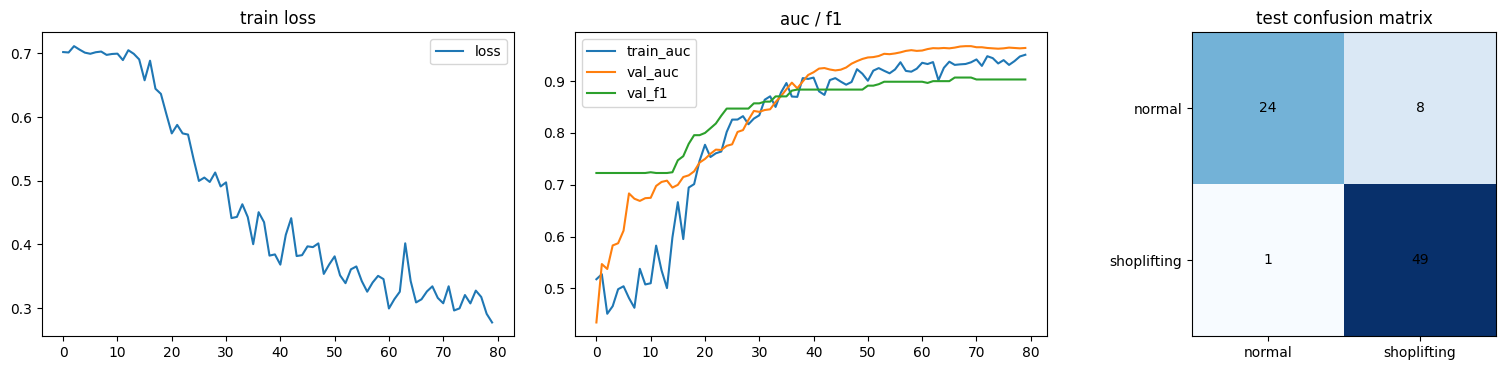

In [34]:
final = Net().to(device)
final.load_state_dict(torch.load(f"{WORK}/best.pt", map_location=device))
pv, yv = predict(final, val_dl, tta=True)
thr, _ = best_thr(yv, pv)
pt, yt = predict(final, test_dl, tta=True)

rows = {}
for name, t in (("threshold 0.5", 0.5), (f"threshold {thr:.2f} (from val)", thr)):
    pred = (pt > t).astype(int)
    rows[name] = dict(accuracy=accuracy_score(yt, pred), precision=precision_score(yt, pred),
                      recall=recall_score(yt, pred), f1=f1_score(yt, pred), auc=roc_auc_score(yt, pt))
print(pd.DataFrame(rows).T.round(4).to_string())

h = pd.DataFrame(hist)
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
h[["loss"]].plot(ax=ax[0], title="train loss")
h[["train_auc", "val_auc", "val_f1"]].plot(ax=ax[1], title="auc / f1")
cm = confusion_matrix(yt, (pt > thr).astype(int))
ax[2].imshow(cm, cmap="Blues"); ax[2].set_title("test confusion matrix")
ax[2].set_xticks([0, 1], ["normal", "shoplifting"]); ax[2].set_yticks([0, 1], ["normal", "shoplifting"])
for (i, j), v in np.ndenumerate(cm):
    ax[2].text(j, i, v, ha="center", va="center", color="black")
plt.tight_layout(); plt.show()